# 01 · Data cleaning and quality checks
**Goal:** turn the raw Telco customer file into a trustworthy analysis table, and record every change.

**Question this notebook answers:** is the data fit to analyse, and what did we have to fix?

In [1]:
import sys; sys.path.insert(0, '../src'); sys.path.insert(0, '../scripts')
import pandas as pd, numpy as np
import style
from churn.data import load_raw, quality_report, clean
from churn.config import CLEAN
pd.set_option('display.width', 140)
raw = load_raw()
raw.shape

(7043, 21)

## 1. First look

In [2]:
raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw.dtypes.to_frame('dtype').T

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype,str,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,str,str


## 2. Quality report on the raw file
`TotalCharges` is read as text, which means it contains something that is not a number.

In [4]:
q = quality_report(raw)
pd.Series(q, name='value').to_frame()

,value
rows,7043.00
columns,21.00
duplicate_rows,0.00
duplicate_customer_ids,0.00
missing_cells_as_read,0.00
total_charges_not_numeric,11.00
total_charges_blank_with_tenure_zero,11.00
churn_rate_pct,26.54


In [5]:
blank = raw[raw['TotalCharges'].str.strip() == '']
blank[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


**Finding.** The 11 blank `TotalCharges` values all belong to customers with `tenure = 0`: they signed up but have not yet been billed. The correct value is 0, not the median or a dropped row. Dropping them would remove 11 customers who are all still active.

## 3. Consistency checks beyond missing values

In [6]:
# Does TotalCharges roughly equal tenure x MonthlyCharges? (it should, unless prices changed)
tc = pd.to_numeric(raw['TotalCharges'], errors='coerce')
expected = raw['tenure'] * raw['MonthlyCharges']
ratio = (tc / expected).replace([np.inf, -np.inf], np.nan).dropna()
print('median billed / expected:', round(ratio.median(), 3))
print('share within +/-25%:', round(((ratio > .75) & (ratio < 1.25)).mean() * 100, 1), '%')
print('customers billed more than 1.5x expected:', int((ratio > 1.5).sum()))

median billed / expected: 1.0
share within +/-25%: 99.6 %
customers billed more than 1.5x expected: 2


In [7]:
# Labels that mean the same thing as 'No'
for c in ['MultipleLines', 'OnlineSecurity', 'StreamingTV']:
    print(c, raw[c].value_counts().to_dict())
print('SeniorCitizen', raw['SeniorCitizen'].value_counts().to_dict())

MultipleLines {'No': 3390, 'Yes': 2971, 'No phone service': 682}
OnlineSecurity {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
StreamingTV {'No': 2810, 'Yes': 2707, 'No internet service': 1526}
SeniorCitizen {0: 5901, 1: 1142}


In [8]:
# Impossible or suspicious values
checks = {
    'tenure outside 0-72': int((~raw['tenure'].between(0, 72)).sum()),
    'MonthlyCharges <= 0': int((raw['MonthlyCharges'] <= 0).sum()),
    'internet add-on but InternetService = No': int(((raw['InternetService'] == 'No') & (raw['OnlineSecurity'] == 'Yes')).sum()),
    'duplicate customerID': int(raw['customerID'].duplicated().sum()),
}
pd.Series(checks, name='rows').to_frame()

,rows
tenure outside 0-72,0
MonthlyCharges <= 0,0
internet add-on but InternetService = No,0
duplicate customerID,0


## 4. Apply the cleaning (see `src/churn/data.py`) and log every change

In [9]:
df, log = clean(raw)
pd.DataFrame(log, columns=['change', 'rows touched'])

,change,rows touched
0,"TotalCharges: blank text -> 0.0 (customers with tenure 0, not billed yet)",11
1,OnlineSecurity: 'No internet/phone service' -> 'No',1526
2,OnlineBackup: 'No internet/phone service' -> 'No',1526
3,DeviceProtection: 'No internet/phone service' -> 'No',1526
4,TechSupport: 'No internet/phone service' -> 'No',1526
5,StreamingTV: 'No internet/phone service' -> 'No',1526
6,StreamingMovies: 'No internet/phone service' -> 'No',1526
7,MultipleLines: 'No internet/phone service' -> 'No',682
8,SeniorCitizen: 0/1 -> No/Yes,7043
9,PaymentMethod: removed ' (automatic)' suffix,3066


In [10]:
print('rows before/after:', len(raw), len(df))
print('missing values after cleaning:', int(df.isna().sum().sum()))
df.dtypes.value_counts().to_frame('columns')

rows before/after: 7043 7043
missing values after cleaning: 0


,columns
str,18
int64,2
float64,2


## 5. Outliers in the numeric columns

,tenure,MonthlyCharges,TotalCharges
count,7043.0,7043.0,7043.0
mean,32.4,64.8,2279.7
std,24.6,30.1,2266.8
min,0.0,18.2,0.0
25%,9.0,35.5,398.6
50%,29.0,70.4,1394.6
75%,55.0,89.8,3786.6
max,72.0,118.8,8684.8


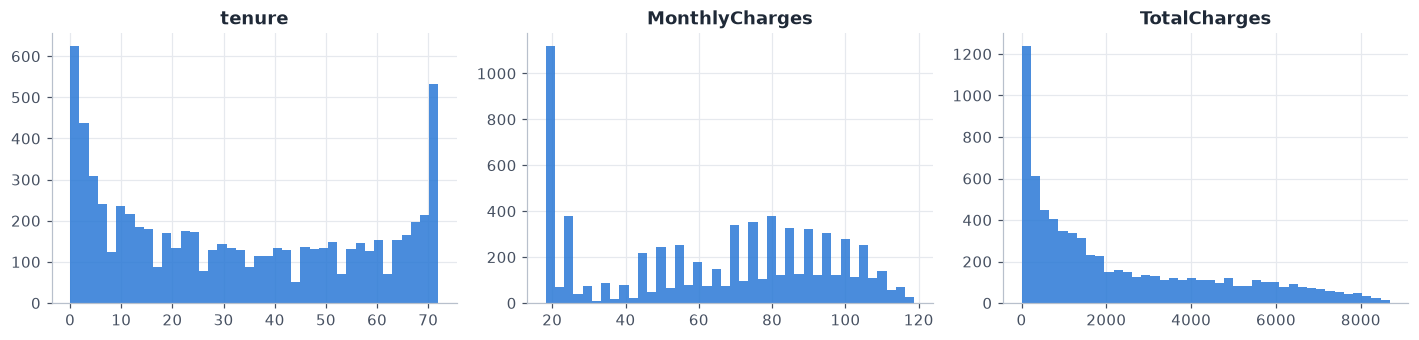

In [11]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, c in zip(ax, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    a.hist(df[c], bins=40, color=style.BLUE, alpha=.85); a.set_title(c)
plt.tight_layout()
df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe().round(1)

**Finding.** No outliers need removing: distributions are plausible (tenure 0-72 months, monthly charges about 18 to 119). `MonthlyCharges` has a spike near 20 (phone-only customers) and `tenure` has peaks at 1 and 72 months, which are real business patterns (new sign-ups and long-term customers), not errors.

## 6. Save the analysis table

In [12]:
CLEAN.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(CLEAN, index=False)
print('saved', CLEAN.name, df.shape)
import json
from churn.config import TABLES
TABLES.mkdir(parents=True, exist_ok=True)
pd.DataFrame(log, columns=['change', 'rows_touched']).to_csv(TABLES / 'cleaning_log.csv', index=False)
with open(TABLES / 'raw_quality_report.json', 'w', encoding='utf-8') as f:
    json.dump(q, f, indent=2)

saved telco_clean.csv (7043, 22)
